# Project 04 · Two-Tower Neural Retrieval for Mortgage Knowledge

**Track:** Deep Learning / Retrieval  
**Research / product question:** Can we match borrowers’ questions to relevant mortgage articles without pairwise inference over every document?

**Learning outcome:** Train query/document embeddings with contrastive learning, evaluate Recall@K and tune embedding dimensions.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

A shared embedding space maps questions and candidate articles to unit-length vectors. Learn retrieval using contrastive negatives and report Recall@K against TF-IDF.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Construct queries, candidate articles and ground-truth intent

We simulate mortgage knowledge topics and multiple phrasings. Query and document encoders are **separate towers**. Repeated-topic in-batch negatives are avoided by building batches with unique topic labels.

In [2]:
# Create labeled query/article pairs, not real customer information.
import re, torch
from torch import nn
torch.manual_seed(42);torch.set_num_threads(2)
topics={
'prepayment':['pay off mortgage early','refinance my loan','early repayment penalty','make an extra principal payment'],
'delinquency':['late mortgage payment','behind on my home loan','missed a payment','mortgage past due'],
'escrow':['property tax escrow','why did escrow increase','homeowners insurance account','escrow shortage'],
'loan_modification':['request loan modification','hardship assistance program','change payment terms','modify my loan'],
'closing_cost':['mortgage closing costs','lender fees at settlement','cost of buying a home','origination charges'],
'interest_rate':['fixed vs adjustable interest','mortgage rates explained','rate lock details','interest payment calculation'],
'credit_score':['credit score mortgage approval','improve borrower credit','credit report underwriting','credit history check'],
'home_equity':['cash out refinance','home equity loan','borrow against home value','equity credit line']}
notes={c:[f'{v} guide and eligibility details for borrowers',f'Frequently asked questions about {v}',f'Overview: {v} explained step by step'] for c,vs in topics.items() for v in [vs[0]]}
articles=pd.DataFrame([(c,j,t) for c,texts in notes.items() for j,t in enumerate(texts)],columns=['topic','doc_id','text'])
questions=pd.DataFrame([(c,f'{rng.choice(questions)} {rng.choice(["please explain","how does it work","what should I know",""])}') for c,questions in topics.items() for _ in range(65)],columns=['topic','query'])
print('Docs',len(articles),'Queries',len(questions));print(questions.head().to_string(index=False))

Docs 24 Queries 520
     topic                                     query
prepayment                   pay off mortgage early 
prepayment  early repayment penalty how does it work
prepayment                        refinance my loan 
prepayment pay off mortgage early what should I know
prepayment     pay off mortgage early please explain


## 2. Tokenization and fixed-length batching

The vocabulary is built from the synthetic public corpus (not labels). Unknown words are mapped to `<UNK>`. Mean-pooling with padding masks is a simple but useful dual-encoder baseline.

In [3]:
# Tokenize using training vocabulary and pad consistently.
def tokens(s):return re.findall(r'[a-z]+',s.lower())
from collections import Counter
cnt=Counter(w for s in pd.concat([questions['query'],articles['text']]) for w in tokens(s))
vocab={'<PAD>':0,'<UNK>':1};vocab.update({w:i+2 for i,(w,_) in enumerate(cnt.most_common())})
def encode(strings,maxlen=15):
 x=np.zeros((len(strings),maxlen),dtype=np.int64)
 for i,s in enumerate(strings):
    ws=[vocab.get(w,1) for w in tokens(s)[:maxlen]];x[i,:len(ws)]=ws
 return torch.tensor(x)
qids=encode(questions['query']);dids=encode(articles['text']);train_ids,val_ids=train_test_split(np.arange(len(questions)),test_size=.25,stratify=questions.topic,random_state=42)
class Tower(nn.Module):
 def __init__(self,vsize,dim):super().__init__();self.emb=nn.Embedding(vsize,dim,padding_idx=0);self.proj=nn.Linear(dim,dim)
 def forward(self,ids):
    e=self.emb(ids);mask=(ids!=0).unsqueeze(-1);v=(e*mask).sum(1)/mask.sum(1).clamp(min=1);return nn.functional.normalize(self.proj(v),dim=-1)
class Dual(nn.Module):
 def __init__(self,vsize,dim):super().__init__();self.q=Tower(vsize,dim);self.d=Tower(vsize,dim)
 def forward(self,q,d):return self.q(q)@self.d(d).T
# Use unique-topic pairs in each batch to avoid marking same-topic docs as false negatives.
by_topic={c:questions.index[questions.topic==c].to_numpy() for c in topics};doc_topic={c:articles.index[articles.topic==c].to_numpy() for c in topics}
train_by={c:np.intersect1d(train_ids,ids) for c,ids in by_topic.items()}

## 3. Train with contrastive cross-entropy and tune embedding size

Each mini-batch contains one query–document positive for each distinct topic. `logits[i,i]` should be highest. The temperature controls contrastive sharpness.

Validation Recall@3: {16: np.float64(1.0), 40: np.float64(1.0)} best dim 16


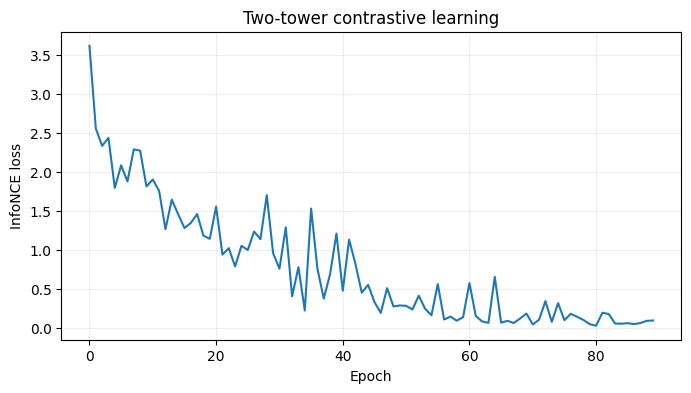

In [4]:
# Train embeddings with in-batch contrastive negatives.
def train_dual(dim,epochs=90,temperature=.12):
 torch.manual_seed(42);model=Dual(len(vocab),dim);opt=torch.optim.AdamW(model.parameters(),lr=.012);history=[]
 for ep in range(epochs):
    qi=[int(rng.choice(train_by[c])) for c in topics]
    di=[int(rng.choice(doc_topic[c])) for c in topics]
    logits=model(qids[qi],dids[di])/temperature
    loss=nn.functional.cross_entropy(logits,torch.arange(len(qi)))
    opt.zero_grad();loss.backward();opt.step();history.append(loss.item())
 return model,history
models={dim:train_dual(dim) for dim in [16,40]}
def recall_at_k(model,query_indices,k=3):
 with torch.no_grad():scores=(model.q(qids[query_indices])@model.d(dids).T).numpy()
 pred=np.argsort(-scores,axis=1)[:,:k];true=questions.iloc[query_indices].topic.to_numpy();labels=articles.topic.to_numpy()
 return np.mean([t in labels[indices] for t,indices in zip(true,pred)])
valid_scores={dim:recall_at_k(model,val_ids) for dim,(model,history) in models.items()}
bestdim=max(valid_scores,key=valid_scores.get);bestmodel,hist=models[bestdim]
print('Validation Recall@3:',valid_scores,'best dim',bestdim)
plt.plot(hist);plt.xlabel('Epoch');plt.ylabel('InfoNCE loss');plt.title('Two-tower contrastive learning');plt.show()

## 4. Retrieval evaluation against TF-IDF

A lexical TF-IDF baseline is often strong for structured knowledge-base content. The neural model must justify its cost and be evaluated on paraphrases and entirely new templates.

TF-IDF validation Recall@3 0.562 Neural 1.0


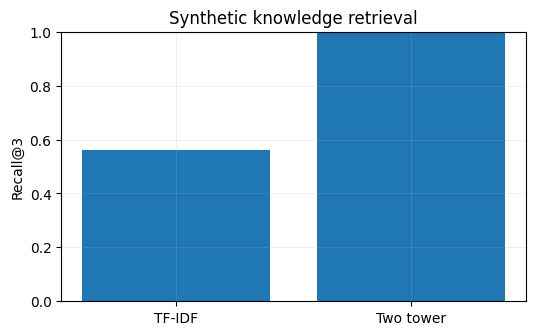

Example query: hardship assistance program 
            topic                                                                  text
loan_modification            Overview: request loan modification explained step by step
loan_modification            Frequently asked questions about request loan modification
loan_modification request loan modification guide and eligibility details for borrowers


In [5]:
# Report Recall@K and inspect the actual retrieved text.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
vec=TfidfVectorizer(ngram_range=(1,2)).fit(pd.concat([questions['query'].iloc[train_ids],articles['text']]))
lex=cosine_similarity(vec.transform(questions['query'].iloc[val_ids]),vec.transform(articles.text))
top=np.argsort(-lex,axis=1)[:,:3];true=questions.topic.iloc[val_ids].to_numpy();topic_array=articles.topic.to_numpy()
base=np.mean([t in topic_array[ids] for t,ids in zip(true,top)])
print('TF-IDF validation Recall@3',round(base,3),'Neural',round(valid_scores[bestdim],3))
fig,ax=plt.subplots(figsize=(6,3.5));ax.bar(['TF-IDF','Two tower'],[base,valid_scores[bestdim]]);ax.set(ylim=(0,1),ylabel='Recall@3',title='Synthetic knowledge retrieval');plt.show()
with torch.no_grad():sim=bestmodel(qids[val_ids[:1]],dids).ravel().numpy()
print('Example query:',questions.query.iloc[val_ids[0]] if False else questions['query'].iloc[val_ids[0]])
print(articles.iloc[np.argsort(-sim)[:3]][['topic','text']].to_string(index=False))

## What the results mean / interview discussion

Dual encoders embed documents once and queries at request time; approximate-nearest-neighbor retrieval is a natural production extension. Our small corpus uses full-matrix retrieval. Since vocab and simulated templates are narrow, this demonstrates mechanics, not language understanding comparable to pretrained embeddings.

**Try explaining these without looking at the code:**

1. Why do two towers scale better than a cross encoder for first-stage retrieval?
2. What is the false-negative problem in in-batch contrastive training?
3. How do Recall@K and downstream answer correctness differ?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Next:** make paraphrases and negatives harder, train on many more documents, and use separate question/document encoders. Near-perfect scores on tiny simulated taxonomies do not imply real-world retrieval performance.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.